# Imports

In [219]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
print("JAX:", jax.__version__)
print("local device count:", jax.local_device_count())
print("local devices:")
for d in jax.local_devices():
    print("  ", d)
    
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

from likelihood import (
    FD_gaussian_likelihood,
    FD_marg_fullnormal_Gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_Gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
)
from model import setup_model

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random

JAX: 0.11.2
local device count: 4
local devices:
   cpu:0
   cpu:1
   cpu:2
   cpu:3


In [28]:
# import sys
# print(sys.executable)  # Should point to your venv path, not /mnt/sw/nix/...

In [29]:
# import tqdm.std

# # Force tqdm to use newlines and flush output instantly for Jupyter
# def line_printer(file):
#     def print_status(s):
#         file.write(s.replace("\r", "") + "\n")
#         file.flush()
#     return print_status

# tqdm.std.status_printer = line_printer

In [4]:
# import sys
# import tqdm.std

# class ThreadSafeStdOut:
#     def __init__(self, stream):
#         self.stream = stream
#     def write(self, s):
#         self.stream.write(s)
#         self.stream.flush()
#     def flush(self):
#         self.stream.flush()

# # Override tqdm's default output file handle
# tqdm.std.tqdm.stqdm_file = ThreadSafeStdOut(sys.stdout)

## Real data

#### Pulling the data

In [5]:
data = jnp.load('/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz')
power, freq, time = data['power'], data['freq'], data['time']
freq = freq[::-1]
power = power[::-1, :]

# Shift to relative time starting at t = 0 (prevents float32 phase rounding)
time_rel = jnp.asarray(time - time[0], dtype=jnp.float32)
freq_channels = jnp.asarray(freq, dtype=jnp.float32)[:, None]
data_reshaped = jnp.asarray(power, dtype=jnp.float32)

Nseg = time_rel.shape[0]
dt = time_rel[1] - time_rel[0]

# Off-pulse noise region (first 20% of time bins)
n_noise_bins = Nseg // 5
noise_data = data_reshaped[:, :n_noise_bins]

# Off-pulse baseline median and MAD estimate of time-domain std dev (sigma_td)
noise_median_estimates = jnp.median(noise_data, axis=1, keepdims=True)
mad = jnp.median(jnp.abs(noise_data - noise_median_estimates), axis=1, keepdims=True)
sigma_estimates = mad * 1.4826  # Time-domain std dev (varsigma_a) per channel

# Baseline subtract off-pulse median
data_reshaped = data_reshaped - noise_median_estimates

# Fourier domain data (d_tilde = dt * rfft(d_td))
data_reshaped_FFT = dt * jnp.fft.rfft(data_reshaped, axis=-1)

# --- CRITICAL: Convert time-domain MAD std dev to Fourier-domain noise std dev ---
# sigma_noise = dt * sigma_td * sqrt(L / 2)
sigma_noise = dt * sigma_estimates * jnp.sqrt(Nseg / 2.0)

# Zero/NaN guard for masked RFI channels
sigma_noise = jnp.where(
    (sigma_noise <= jnp.float32(0.0)) | jnp.isnan(sigma_noise),
    jnp.inf,
    sigma_noise,
)

# Setup unmarginalized likelihood, model and sampler

In [327]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": float(jnp.mean(freq_channels)),
    "delta": -4.0,
    "DM_incoherent": 0.0,#328.5999195049641,#0.0,
    "channel_width": float(jnp.abs(freq[1] - freq[0])),
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------

# test_params = {
#     "mean_arrival_time": jnp.float32(0.00115),  # (s)
#     "sigma": jnp.float32(9.9871264e-05),             # (s)
#     "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
#     "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
#     "gamma": jnp.float32(-5.6108313),               # spectral index
#     "beta": jnp.float32(-2.6474257),                # spectral running
#     "freq_ref": jnp.float32(600)
# }

# priors = {
#     #PRIORS THAT WORK WITH D_INC=0
#     "mean_arrival_time": dist.Uniform(0.00115-.001, 0.00115+.001),
    
#     "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
#     "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-5, 1e-3),            # scattering timescale (s)
#     "gamma": dist.Uniform(-20.0, 1.0),             # spectral index
#     "beta": dist.Uniform(-20.0, 1.0),                # spectral running
#     "A": dist.Uniform(1e-5,1e-3)
# }
# priors = {
#     #PRIORS THAT WORK WITH D_INC=0
#     "mean_arrival_time": dist.Uniform(0.00115-.001, 0.00115+.001),
    
#     "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
#     "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-5, 1e-3),            # scattering timescale (s)
#     "gamma": dist.Uniform(-20.0, 1.0),             # spectral index
#     "beta": dist.Uniform(-20.0, 1.0),                # spectral running
#     "A": dist.Uniform(1e-5,1e-3)
# }

priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),
    
    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-4),            # scattering timescale (s)
    "gamma": dist.Uniform(-10.0, -2.0),             # spectral index
    "beta": dist.Uniform(-8.0, 1.0),                # spectral running
    "A": dist.Uniform(1e-5,1e-3)

}
n_pulses = 1

num_warmup = 200
num_samples = 200
num_chains = 1

kernel = NUTS(FD_gaussian_likelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

# Run Unmarginalized Full normal

In [328]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 400/400 [00:58<00:00,  6.80it/s, 31 steps of size 2.07e-01. acc. prob=0.93]  


In [329]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [330]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [331]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,101.441,103.086,NaN,0.000,0.000
DM[0],-0.007,0.000,-0.008,-0.007,140.649,93.583,NaN,0.000,0.000
beta[0],-7.960,0.038,-7.999,-7.888,93.112,84.765,NaN,0.004,0.003
gamma[0],-9.578,0.058,-9.667,-9.492,80.496,82.709,NaN,0.007,0.004
mean_arrival_time[0],0.001,0.000,0.001,0.001,116.111,96.996,NaN,0.000,0.000
sigma[0],0.000,0.000,0.000,0.000,71.904,96.023,NaN,0.000,0.000
tau_ref[0],0.000,0.000,0.000,0.000,137.838,127.039,NaN,0.000,0.000


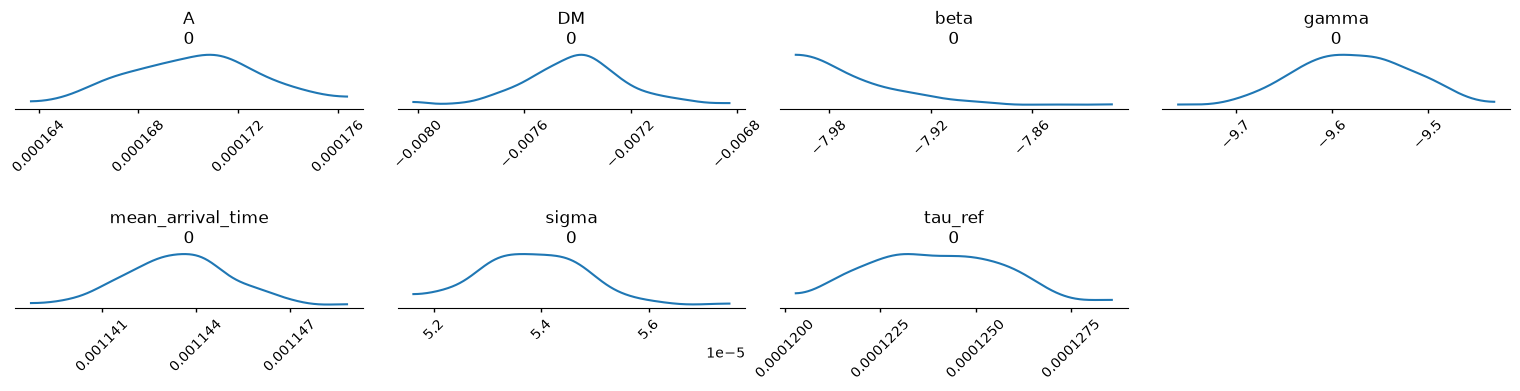

In [332]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

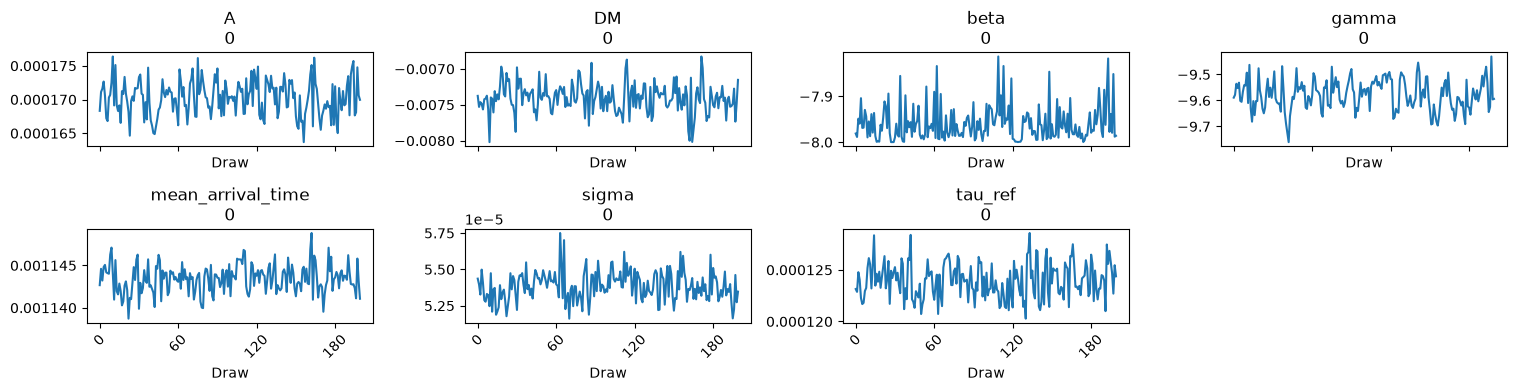

In [333]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Plot Residual

Plotting for Posterior Draw #178
Max Data abs : 26.971832
Max Model abs: 2.9173262


/tmp/ipykernel_3342559/612648999.py:118: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


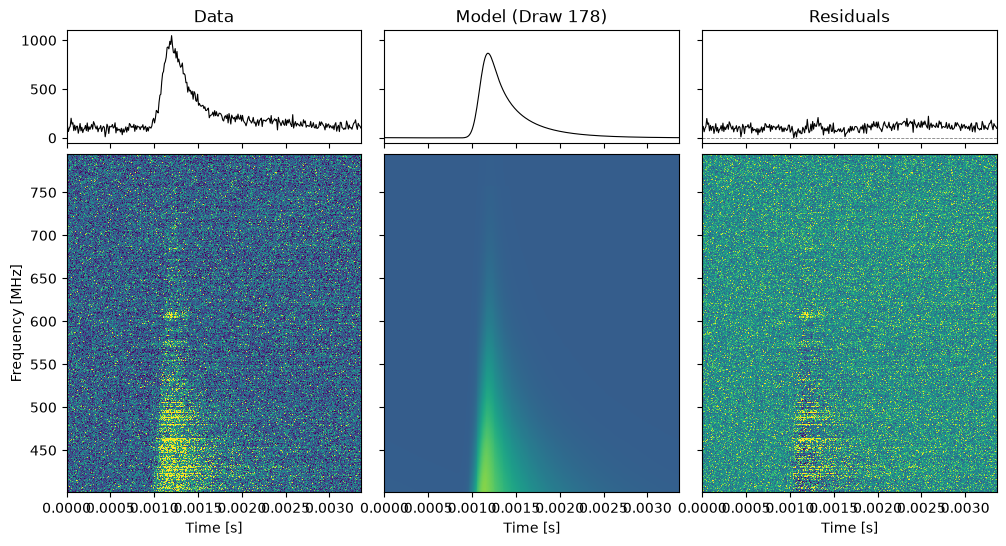

In [334]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Squeeze Parameters to Scalars
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

draw_idx = random.randint(0, num_draws - 1)
print(f"Plotting for Posterior Draw #{draw_idx}")

# Use jnp.squeeze to strip trailing (1,) dimensions from parameters
test_params = {
    "mean_arrival_time": jnp.squeeze(samples["mean_arrival_time"][draw_idx]),
    "sigma": jnp.squeeze(samples["sigma"][draw_idx]),
    "DM": jnp.squeeze(samples["DM"][draw_idx]),
    "tau_ref": jnp.squeeze(samples["tau_ref"][draw_idx]),
    "gamma": jnp.squeeze(samples["gamma"][draw_idx]),
    "beta": jnp.squeeze(samples["beta"][draw_idx]),
    "freq_ref": jnp.float32(600.0),
    "A": jnp.squeeze(samples["A"][draw_idx]),
}

# Forward model evaluation
M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# Quick amplitude check diagnostic
print("Max Data abs :", jnp.max(jnp.abs(data_TD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_TD_plot)))

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_TD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

# Run Unmarginalized half normal

In [328]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 400/400 [00:58<00:00,  6.80it/s, 31 steps of size 2.07e-01. acc. prob=0.93]  


In [329]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [330]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [331]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,101.441,103.086,NaN,0.000,0.000
DM[0],-0.007,0.000,-0.008,-0.007,140.649,93.583,NaN,0.000,0.000
beta[0],-7.960,0.038,-7.999,-7.888,93.112,84.765,NaN,0.004,0.003
gamma[0],-9.578,0.058,-9.667,-9.492,80.496,82.709,NaN,0.007,0.004
mean_arrival_time[0],0.001,0.000,0.001,0.001,116.111,96.996,NaN,0.000,0.000
sigma[0],0.000,0.000,0.000,0.000,71.904,96.023,NaN,0.000,0.000
tau_ref[0],0.000,0.000,0.000,0.000,137.838,127.039,NaN,0.000,0.000


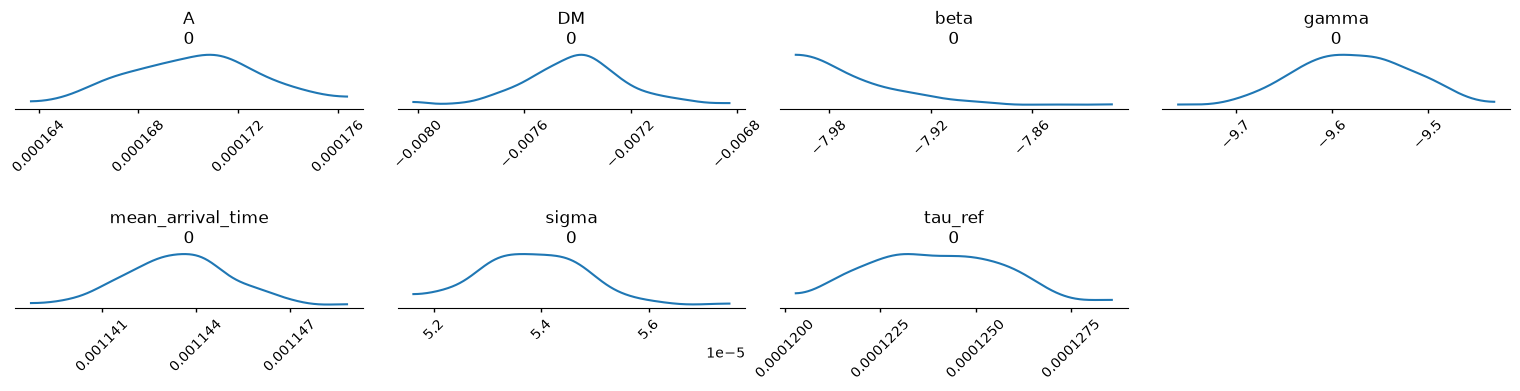

In [332]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

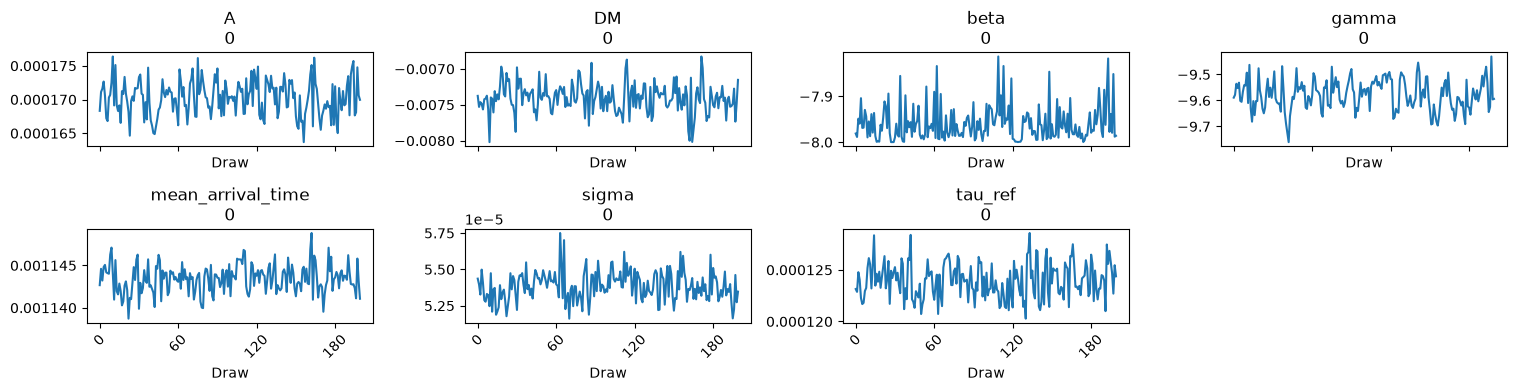

In [333]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Plot Residual

Plotting for Posterior Draw #178
Max Data abs : 26.971832
Max Model abs: 2.9173262


/tmp/ipykernel_3342559/612648999.py:118: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


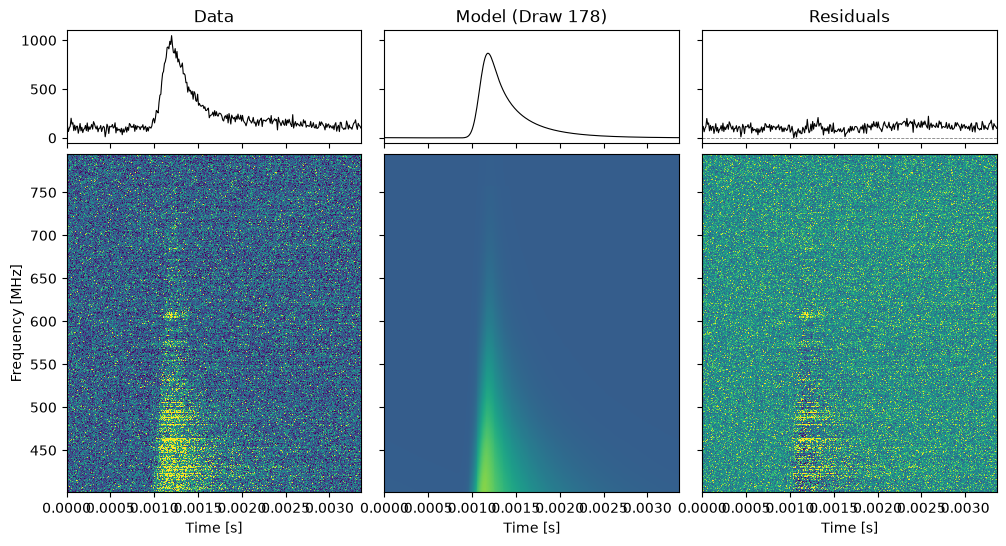

In [334]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Squeeze Parameters to Scalars
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

draw_idx = random.randint(0, num_draws - 1)
print(f"Plotting for Posterior Draw #{draw_idx}")

# Use jnp.squeeze to strip trailing (1,) dimensions from parameters
test_params = {
    "mean_arrival_time": jnp.squeeze(samples["mean_arrival_time"][draw_idx]),
    "sigma": jnp.squeeze(samples["sigma"][draw_idx]),
    "DM": jnp.squeeze(samples["DM"][draw_idx]),
    "tau_ref": jnp.squeeze(samples["tau_ref"][draw_idx]),
    "gamma": jnp.squeeze(samples["gamma"][draw_idx]),
    "beta": jnp.squeeze(samples["beta"][draw_idx]),
    "freq_ref": jnp.float32(600.0),
    "A": jnp.squeeze(samples["A"][draw_idx]),
}

# Forward model evaluation
M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# Quick amplitude check diagnostic
print("Max Data abs :", jnp.max(jnp.abs(data_TD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_TD_plot)))

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_TD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Test priors

/tmp/ipykernel_3342559/3600792235.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


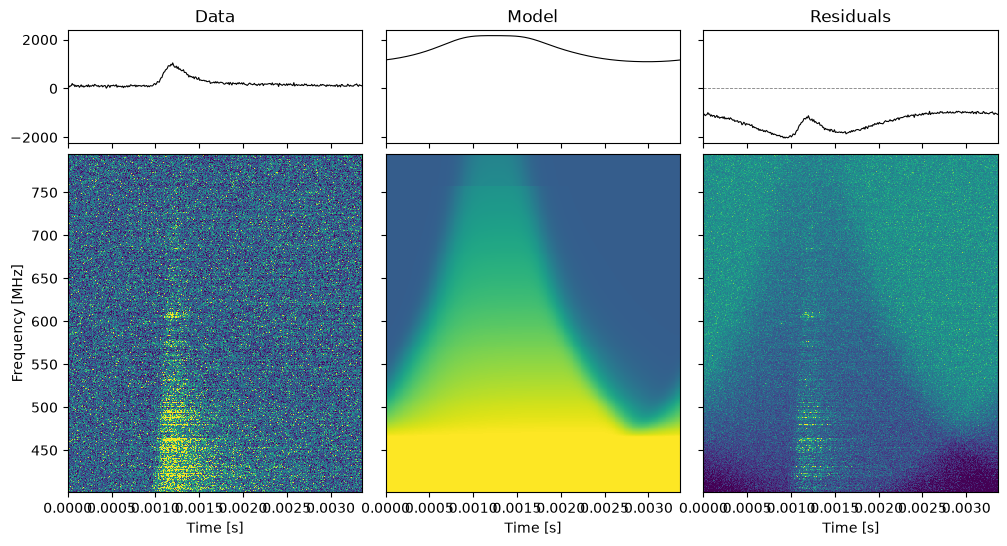

In [293]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),  # (s)
    "DM": jnp.float32(-0.01),  # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),  # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),  # spectral index
    "beta": jnp.float32(-2.6474257),  # spectral running
    "freq_ref": jnp.float32(600.0),  # (MHz)
    "A": jnp.float32(4e-4*10),  # Explicit unmarginalized amplitude
}

# Evaluate unmarginalized Fourier model directly (A is inside test_params)
M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Color limits: data/model scale vs. zero-centered residual scale
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))
vmax_res = jnp.nanpercentile(jnp.abs(resid_TD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",  # Symmetric zero-centered colormap
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

# Setup marginalized model and sampler

In [297]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": float(jnp.mean(freq_channels)),
    "delta": -4.0,
    "DM_incoherent": 0.0,
    "channel_width": float(jnp.abs(freq[1] - freq[0])),
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------
# priors = {
#     "mean_arrival_time": dist.Uniform(0.05, 0.06),   # (s) across window
#     "sigma": dist.Uniform(5e-5, 5e-4),               # intrinsic width (s)
#     "DM": dist.Uniform(-0.05, 0.04),                 # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-4, 2.5e-4),           # scattering timescale (s)
#     "gamma": dist.Uniform(-8.0, -6.0),               # spectral index
#     "beta": dist.Uniform(-6.0, -4.0),                # spectral running
# }

# test_params = {
#     "mean_arrival_time": jnp.float32(0.00115),  # (s)
#     "sigma": jnp.float32(9.9871264e-05),             # (s)
#     "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
#     "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
#     "gamma": jnp.float32(-5.6108313),               # spectral index
#     "beta": jnp.float32(-2.6474257),                # spectral running
#     "freq_ref": jnp.float32(600)
# }

priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),
    
    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-4),            # scattering timescale (s)
    "gamma": dist.Uniform(-10.0, -2.0),             # spectral index
    "beta": dist.Uniform(-8.0, 1.0),                # spectral running
}
n_pulses = 1
s_opt = 100.0

num_warmup = 100
num_samples = 100
num_chains = 1

kernel = NUTS(FD_marg_fullnormal_Gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

# Run Marginalized

In [298]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 200/200 [04:15<00:00,  1.28s/it, 799 steps of size 6.25e-03. acc. prob=0.97] 


In [299]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [300]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [301]:
az.summary(mcmc_data, round_to=3)

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in scalar power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: invalid value encountered in scalar subtract
  varvar = ((sims_c**4).mean() - evar**2) / ess


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-8.000000e-03,-7.000000e-03,72.930,75.664,NaN,0.000000e+00,0.000
beta[0],-7.960000e+00,3.200000e-02,-7.998000e+00,-7.903000e+00,17.804,25.945,NaN,5.000000e-03,0.003
gamma[0],-9.571000e+00,6.200000e-02,-9.679000e+00,-9.481000e+00,90.119,74.754,NaN,7.000000e-03,0.005
"gram[0, 0]",1.425590e+12,4.511158e+10,1.351335e+12,1.503043e+12,102.250,73.410,NaN,4.571220e+09,NaN
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,83.322,75.664,NaN,0.000000e+00,0.000
rho_mf[0],2.432827e+08,3.846079e+06,2.368748e+08,2.498275e+08,101.863,73.410,NaN,3.886939e+05,310822.011
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,34.303,17.750,NaN,0.000000e+00,0.000
snr_mf[0],2.037830e+02,1.000000e-02,2.037660e+02,2.037950e+02,33.786,35.785,NaN,2.000000e-03,0.001
snr_opt[0],1.193832e+06,1.887229e+04,1.162465e+06,1.225987e+06,102.250,73.410,NaN,1.907788e+03,1526.359
tau_ref[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,81.822,64.859,NaN,0.000000e+00,0.000


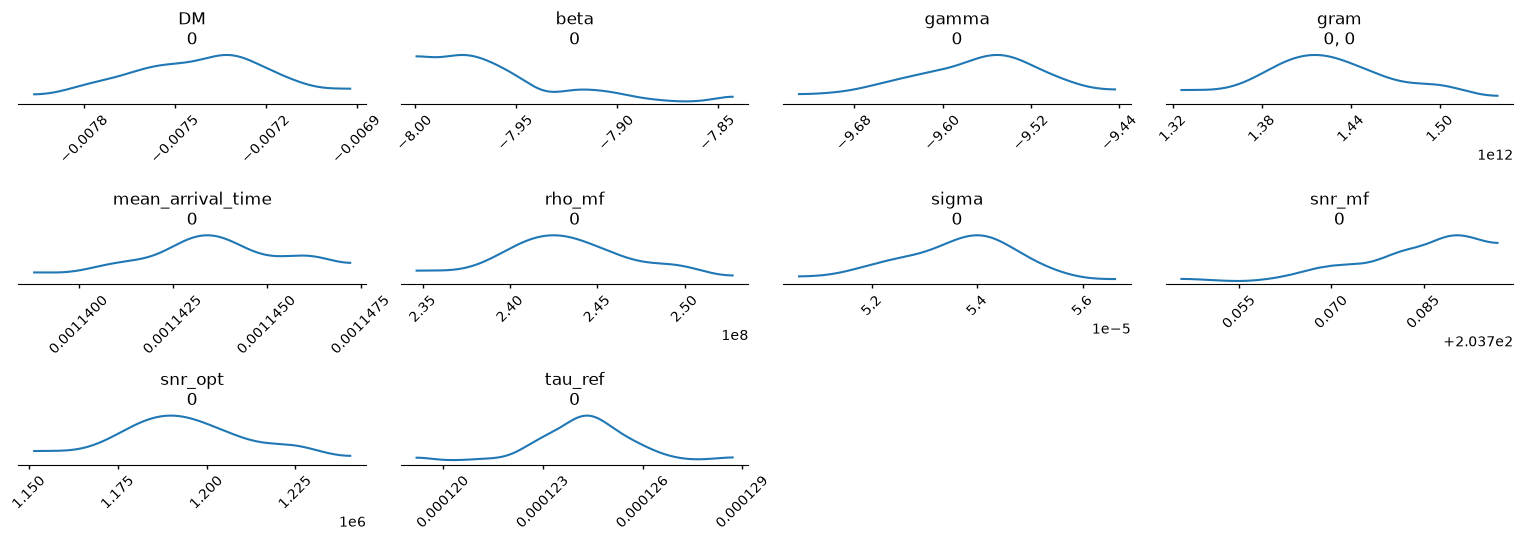

In [302]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

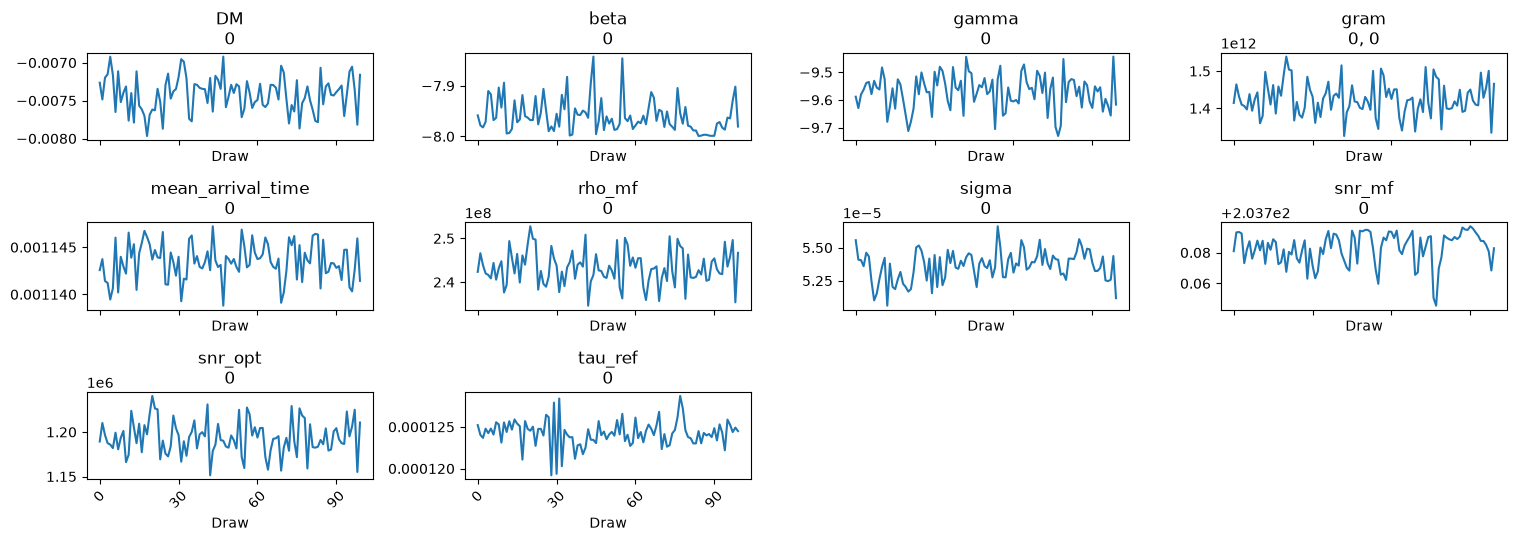

In [303]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [304]:
# -------------------------------------------------------------------
# 4. Reconstruct Fluences
# -------------------------------------------------------------------

fluences, accepts = draw_fluences_fullnormal_gaussmarg(
    gram=samples["gram"],
    rho=samples["rho_mf"],
    s_opt=s_opt,
    key=key_fluences,
)

physical_fluences = fluences[accepts]
print(f"Sampling complete. Retained {jnp.sum(accepts)} / {len(accepts)} physical fluence draws.")

Sampling complete. Retained 100 / 100 physical fluence draws.


In [308]:
physical_fluences

Array([[0.0001696 ],
       [0.00016774],
       [0.00016977],
       [0.00017008],
       [0.00017256],
       [0.00017242],
       [0.00016928],
       [0.00017076],
       [0.00017001],
       [0.00016998],
       [0.00017504],
       [0.00017183],
       [0.00016702],
       [0.00016775],
       [0.00017153],
       [0.00016941],
       [0.00017428],
       [0.00016967],
       [0.00017017],
       [0.00016898],
       [0.0001649 ],
       [0.00016716],
       [0.00016465],
       [0.0001744 ],
       [0.00017103],
       [0.0001731 ],
       [0.00017338],
       [0.00017243],
       [0.00016746],
       [0.00016825],
       [0.0001711 ],
       [0.00017401],
       [0.00017217],
       [0.00017218],
       [0.00017127],
       [0.00016803],
       [0.00016699],
       [0.00017218],
       [0.00017058],
       [0.00016923],
       [0.00017114],
       [0.00016502],
       [0.00017669],
       [0.0001732 ],
       [0.00017305],
       [0.00016973],
       [0.00017027],
       [0.000

## Plot Residual

In [305]:
A_scale=4e-4

Plotting for Posterior Draw #89


/tmp/ipykernel_3342559/2646235761.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


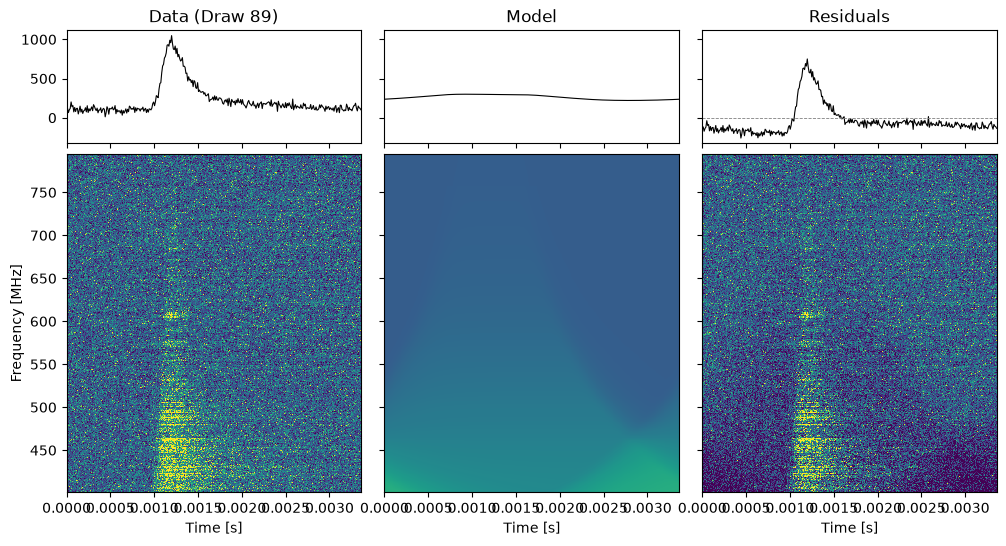

In [313]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "gamma": samples["gamma"][draw_idx],
    "beta": samples["beta"][draw_idx],
    "freq_ref": jnp.float32(600.0),
}

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else jnp.float32(4e-4)
# )

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title(f"Data (Draw {draw_idx})")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Test priors

/tmp/ipykernel_3740517/1299604607.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


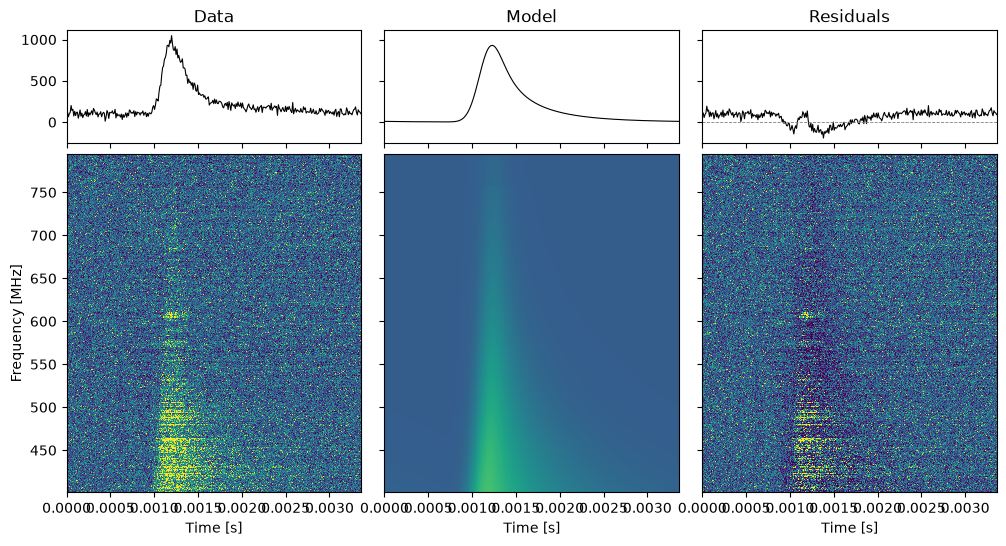

In [26]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
# Set test parameters matching your prior bounds
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),             # (s)
    "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),               # spectral index
    "beta": jnp.float32(-2.6474257),                # spectral running
    "freq_ref": jnp.float32(600)
}

# Optional fluence scale (unit-template from setup_model scaled to data level)
A_scale = 4e-4

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

# Convert to NumPy for Matplotlib rendering
data_TD_plot = np.asarray(data_TD)
model_TD_plot = np.asarray(M_TD)
time_plot = np.asarray(time_rel)
freq_plot = np.asarray(freq).squeeze()

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = np.nansum(data_TD_plot, axis=0)
model_ts = np.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits
lo_pct, hi_pct = 1, 99
vmin, vmax = np.nanpercentile(data_TD_plot, [lo_pct, hi_pct])

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 3,
    height_ratios=[1, 3],
    hspace=0.05, wspace=0.08,
    figure=fig,
)

ax_ts_data  = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data  = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()